In [3]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)
print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 2.2.3 | numpy 2.4.6


In [4]:
import os
FILE = 'tourism_dataset.csv'

if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError('Letakkan CSV di folder yang sama dengan notebook ini.')
print('Siap:', os.path.exists(FILE))

Siap: True


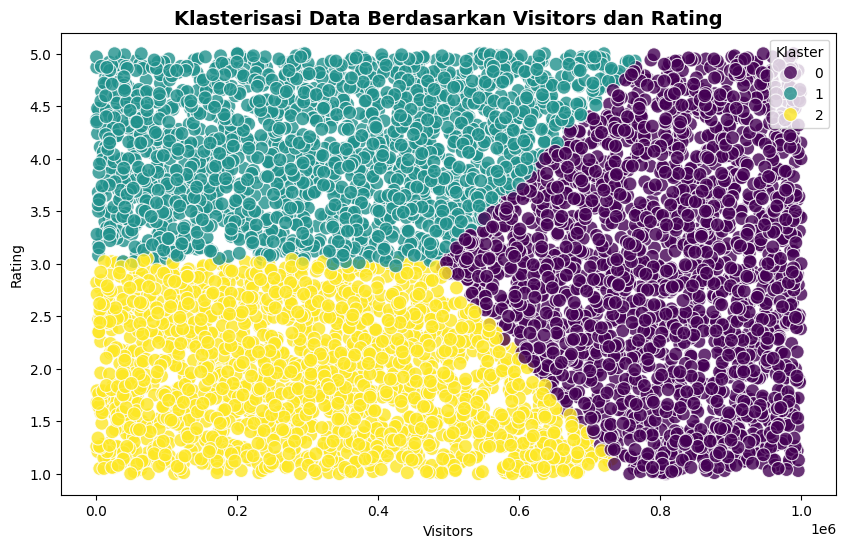

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import statsmodels.formula.api as smf

# Membaca dataset
df = pd.read_csv(FILE)

# A. Pilih kolom numerik untuk diklaster
kolom_cluster = df.select_dtypes(include=['number']).columns
if 'Location_ID' in kolom_cluster:
  kolom_cluster = kolom_cluster.drop('Location_ID')

# B. Standardisasi data (karena K-Means sensitif terhadap skala satuan)
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df[kolom_cluster].dropna())

# C. Terapkan K-Means (misal: membagi menjadi 3 klaster)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(df_scaled)

# D. Visualisasikan hasil klaster dengan Scatter Plot (mengambil 2 kolom numerik pertama)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x=kolom_cluster[0],
    y=kolom_cluster[1],
    hue='Cluster',
    palette='viridis',
    s=100,
    alpha=0.8,
)
plt.title(
    f'Klasterisasi Data Berdasarkan {kolom_cluster[0]} dan {kolom_cluster[1]}',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel(kolom_cluster[0])
plt.ylabel(kolom_cluster[1])
plt.legend(title='Klaster')
plt.show()

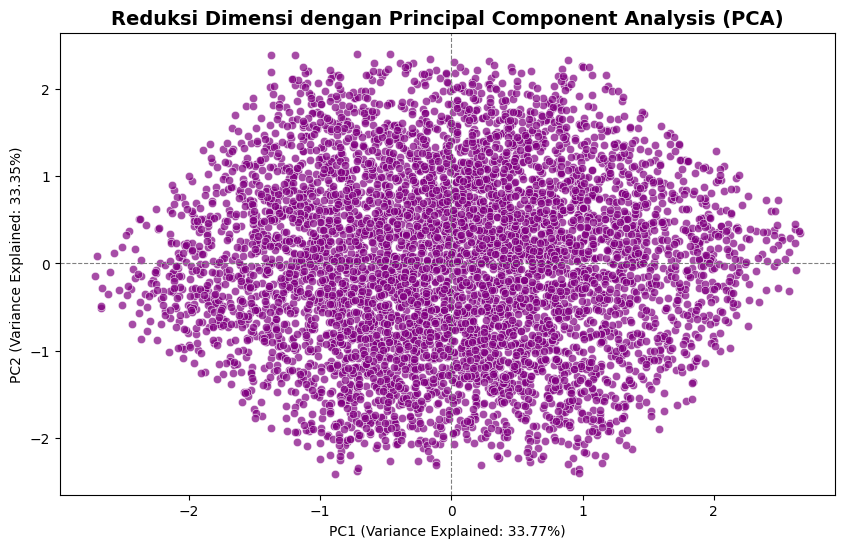

In [7]:
# A. Jalankan PCA untuk mereduksi ke 2 komponen utama (PC1 dan PC2)
pca = PCA(n_components=2)
principal_components = pca.fit_transform(df_scaled)

df_pca = pd.DataFrame(
    data=principal_components, columns=['Principal Component 1', 'Principal Component 2']
)

# B. Visualisasikan hasil PCA
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_pca,
    x='Principal Component 1',
    y='Principal Component 2',
    alpha=0.7,
    color='purple',
)
plt.title(
    'Reduksi Dimensi dengan Principal Component Analysis (PCA)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel(
    f'PC1 (Variance Explained: {pca.explained_variance_ratio_[0]*100:.2f}%)'
)
plt.ylabel(
    f'PC2 (Variance Explained: {pca.explained_variance_ratio_[1]*100:.2f}%)'
)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)
plt.show()

In [8]:
# Tentukan variabel Target (Y) dan Prediktor (X)
# Contoh: Mencari faktor yang memengaruhi 'Rating' (sesuaikan dengan kolom di data Anda)
target_y = 'Rating'  # Ganti dengan kolom numerik target Anda
prediktor_x = [
    col
    for col in kolom_cluster
    if col != target_y and col != 'Location_ID'
]

# Pastikan data bersih dari nilai kosong
df_reg = df[[target_y] + prediktor_x].dropna()

# Buat formula regresi secara dinamis
formula = f"{target_y} ~ " + " + ".join(prediktor_x)

# Jalankan Ordinary Least Squares (OLS) Regression
model = smf.ols(formula=formula, data=df_reg).fit()

# Tampilkan ringkasan hasil regresi
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Rating   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.3212
Date:                Mon, 09 Nov 2026   Prob (F-statistic):              0.725
Time:                        01:57:04   Log-Likelihood:                -9365.3
No. Observations:                5989   AIC:                         1.874e+04
Df Residuals:                    5986   BIC:                         1.876e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.0287      0.039     76.767      0.0

In [ ]:
# Sesuaikan nama kolom numerik dan kategorikal
kolom_num_x = kolom_cluster[0]
kolom_num_y = kolom_cluster[1]
kolom_kat = (
    'Kategori' if 'Kategori' in df.columns else df.select_dtypes(include=['object']).columns[0]
)

g = sns.FacetGrid(df, hue=kolom_kat, height=6, aspect=1.3, palette='Set1')
g.map(sns.scatterplot, kolom_num_x, kolom_num_y, s=80, alpha=0.7)
g.add_legend(title=kolom_kat)
plt.subplots_adjust(top=0.9)
g.fig.suptitle(
    f'Hubungan {kolom_num_x} vs {kolom_num_y} Berdasarkan {kolom_kat}',
    fontsize=14,
    fontweight='bold',
)
plt.show()